# SEM equations · choosing one, and the models it takes

`sweep.sem` has twenty-three equation classes. They all run through the same
`PropSEM(Equation, shape=..., ...)` and the same call, so the choice is about the
physics and about which backend can run it. This notebook:

1. **Reads the equation table** — what the names mean and what each column says
2. **Asks each equation what it needs** — `models=`, default source and receiver, backend
3. **Runs four 2-D equations on one model** — two acoustic, two elastic — and compares the records
4. **Runs the SH equation** — the out-of-plane shear motion, on the same model

About a minute on a GPU, most of it compiling the eager steps on first use.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

import sweep.sem as sem
from sweep.sem import PropSEM, suggest_discretization
from sweep.sem.equations import (describe, AcousticPotentialSEM2D,
                                 AcousticSEM2DDeformed, ElasticSEM2DDeformed,
                                 ElasticVSSEM2DDeformed, ElasticSHSEM2DDeformed)
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. The equation table

`describe()` prints one line per equation (`sweep list equations` and
`sweep show <Equation>` print the same from the command line):

In [2]:
print(describe())

  equation                   mesh   D  topo  cpml  flds  records
  --------------------------------------------------------------
  AcousticElasticSEM2D       quad9  2   yes split    20  chi, u_x, u_z
  AcousticPotentialSEM2D     quad9  2   yes   yes     6  chi
  AcousticSEM2D              quad4  2    no   yes     6  u
  AcousticSEM2DDeformed      quad9  2   yes   yes     6  u
  AcousticSEM3D              hex8   3    no   yes     8  u
  AcousticSEM3DDeformed      hex27  3   yes   yes     8  u
  BiotAnisoPermSEM2DDeformed quad9  2   yes   yes    22  v_x, v_z, p, q_x, q_z, sigma_xx, sigma_zz, sigma_xz
  BiotVSSEM2DDeformed        quad9  2   yes   yes    22  v_x, v_z, p, q_x, q_z, sigma_xx, sigma_zz, sigma_xz
  BiotVSSEM3DDeformed        hex27  3   yes   yes    40  v_x, v_y, v_z, p, q_x, q_y, q_z, sigma_xx, sigma_yy, sigma_zz, sigma_xy, sigma_xz, sigma_yz
  ElasticSEM2D               quad4  2    no    NO     4  u_x, u_z
  ElasticSEM2DDeformed       quad9  2   yes   yes    10  u_x, u_z
  E

How to read it:

- **the name** — `Acoustic`, `Elastic`, `Biot` (poroelastic) or `AcousticElastic`
  (fluid–solid coupled); `VS` = first-order velocity–stress, otherwise
  second-order in displacement (or pressure); `VTI` / `TTI` = transversely
  isotropic with a vertical / tilted symmetry axis; `SH` = the out-of-plane
  shear motion; `Visco` = with attenuation (standard linear solids, the models
  end in quality factors); `Potential` = SPECFEM's fluid potential form; `3D` or `2D`.
- **mesh** — `quad4` / `hex8` are flat, axis-aligned meshes; `quad9` / `hex27`
  are deformable and accept `topography` (the **topo** column).
- **cpml** — whether the equation carries `PropSEM`'s C-PML absorbing layer.
  The three with `NO` (`ElasticSEM2D`, `ElasticSEM3D`, `ElasticSEM3DDeformed`) only
  run as a closed, reflecting box (`abcn=0`); use their `Deformed` or `VS`
  siblings for open models. `split` = an acoustic and an elastic profile, built
  for you.
- **flds / records** — the number of state fields, and the ones a receiver can
  record directly. Derived receivers (`p`, `vx`, `vz`, the strain and the
  rotation) come on top; see the next notebook.

## 2. What each equation needs

A constructed solver reports what it takes: `model_names` is the `models=` list in
order, `impl` the backend it resolved to (`'c'` = the CUDA kernels, `'eager'` =
PyTorch), and `source_type` / `receiver_type` the defaults. Building a solver is
cheap, so we build each on a small grid:

In [3]:
rows = []
for name, cls in sorted(sem.equations.equation_classes().items()):
    ndim = sem.equations.summary(cls)['ndim']
    shape = (17,) * ndim
    try:
        s = PropSEM(cls, shape=shape, dh=10.0, dt=1e-3, abcn=8, device=device)
        rows.append((name, ', '.join(s.model_names), s.impl,
                     ','.join(s.source_type), ','.join(s.receiver_type)))
    except NotImplementedError:
        rows.append((name, '(no C-PML: abcn=0 only)', '', '', ''))

print(f"{'equation':28s} {'models=':42s} {'impl':6s} {'source':12s} receivers")
for r in rows:
    print(f'{r[0]:28s} {r[1]:42s} {r[2]:6s} {r[3]:12s} {r[4]}')

equation                     models=                                    impl   source       receivers
AcousticElasticSEM2D         vp, vs, rho                                c      chi          p,vx,vz
AcousticPotentialSEM2D       vp                                         c      chi          p
AcousticSEM2D                vp                                         eager  u            u
AcousticSEM2DDeformed        vp                                         eager  u            u
AcousticSEM3D                vp                                         c      u            u
AcousticSEM3DDeformed        vp                                         c      u            u
BiotAnisoPermSEM2DDeformed   H, mu, C, M, rho, rho_f, m, b_xx, b_xz, b_zz c      sxx,szz      v_x,v_z
BiotVSSEM2DDeformed          H, mu, C, M, rho, rho_f, m, b              c      sxx,szz      v_x,v_z
BiotVSSEM3DDeformed          H, mu, C, M, rho, rho_f, m, b              c      sxx,syy,szz  v_x,v_y,v_z
ElasticSEM2D          

Things worth knowing from this table:

- **`impl='c'`** (fused CUDA kernels, on a GPU) exists for every equation but
  `AcousticSEM2D`, `AcousticSEM2DDeformed`, `ElasticSEM2D`,
  `ElasticSHSEM2DDeformed`, `ViscoAcousticPotentialSEM2D` and `ViscoElasticSEM2DDeformed`, which run eager (compiled PyTorch), on the GPU or
  the CPU. `impl='eager'` forces eager for any equation.
- **Acoustic models** are `[vp]` with a constant density (`density=` on
  `PropSEM`, default 1000). **Elastic** ones are `[vp, vs, rho]`; VTI adds
  Thomsen's `epsilon, delta`, TTI also the tilt `theta`, and the visco-elastic
  ones two quality factors (`Qp, Qs` on the velocity–stress form, `Qk, Qmu` on
  the displacement form). SH takes `[vs, rho]`. **Biot** takes its eight
  poroelastic coefficients (build them with `sweep.equations.biot.biot_from_rock`).
- On the acoustic forms the wavelet is the **pressure source**, and the potential
  forms record the pressure `p` by default.
- Every model is a grid tensor with the shape of `shape`, like on `PropTorch`.

A practical shortlist for 2-D:

| you want | use | backend |
| --- | --- | --- |
| acoustic modelling / FWI, fast, many shots | `AcousticPotentialSEM2D` | `'c'` |
| acoustic, simplest pressure form | `AcousticSEM2DDeformed` (`AcousticSEM2D` if flat) | eager |
| elastic modelling / FWI, fast | `ElasticSEM2DDeformed` | `'c'` |
| elastic with stress sources / velocity–stress | `ElasticVSSEM2DDeformed` | `'c'` |
| SH (out-of-plane) waves | `ElasticSHSEM2DDeformed` | eager |
| VTI or tilted TI elastic | `ElasticVTISEM2DDeformed`, `ElasticTTISEM2DDeformed` | `'c'` |
| attenuation, velocity–stress | `ViscoElasticVSSEM2DDeformed` | `'c'` |
| attenuation, acoustic or displacement form | `ViscoAcousticPotentialSEM2D`, `ViscoElasticSEM2DDeformed` | eager |
| water over an elastic sea floor | `AcousticElasticSEM2D` | `'c'` |
| poroelastic | `BiotVSSEM2DDeformed` (`ViscoBiotVSSEM2DDeformed` with an attenuating frame) | `'c'` |

The attenuating classes have their own notebook,
[Attenuation · nonlinear Q fit, attenuating C-PML](../49_sem_attenuation/).

## 3. Four equations on one model

A two-layer model with a free surface on top: a source 200 m deep and a line
of receivers 20 m deep. The acoustic equations see `vp` only; the elastic ones see
`vp, vs, rho`.

In [4]:
dh, n_order = 10.0, 4
shape = (97, 193)                          # 960 m x 1920 m, 24 x 48 elements
f0 = 8.0
d = suggest_discretization((shape[1] - 1) * dh, (shape[0] - 1) * dh,
                           v_min=1000.0, v_max=2500.0, f0=f0, n_order=n_order)
print(d)
dt = 0.8e-3                                # just below the suggested step
nt = 1500

vp  = torch.full(shape, 1800.0); vp[48:]  = 2500.0
vs  = torch.full(shape, 1000.0); vs[48:]  = 1400.0
rho = torch.full(shape, 2000.0); rho[48:] = 2200.0
vp, vs, rho = (m.to(device) for m in (vp, vs, rho))

wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[shape[1] // 2, 20]])                      # [ix, iz]
rx = np.arange(4, shape[1] - 4, 2)
rec = np.stack([rx, np.full_like(rx, 2)], axis=1)[None]   # (1, nrec, 2)
print('sources', src.shape, ' receivers', rec.shape)

SEMDiscretization(n_order=4, nex=48, nez=24, dt=8.20e-04  |  λ_min=50.0 m, h_e≈40×40 m, 5.0 pts/λ)


sources (1, 2)  receivers (1, 93, 2)


The acoustic equations record the pressure `p`: on the pressure form it is the
field `u` itself, on the potential form `-d²chi/dt²`, which `PropSEM` records
without differencing. The elastic ones record the vertical particle velocity
(`['vz']`) of a vertical point force (`['vz']`), the same names on both.
Everything else is the same call:

In [5]:
runs = {
    'AcousticPotentialSEM2D': (AcousticPotentialSEM2D, [vp],          ['p']),
    'AcousticSEM2DDeformed':  (AcousticSEM2DDeformed,  [vp],          ['p']),
    'ElasticSEM2DDeformed':   (ElasticSEM2DDeformed,   [vp, vs, rho], ['vz']),
    'ElasticVSSEM2DDeformed': (ElasticVSSEM2DDeformed, [vp, vs, rho], ['vz']),
}
records = {}
for name, (eq, models, rtype) in runs.items():
    kw = {} if eq in (AcousticPotentialSEM2D, AcousticSEM2DDeformed) else \
         dict(source_type=['vz'])
    solver = PropSEM(eq, shape=shape, dh=dh, dt=dt, n_order=n_order, abcn=40,
                     free_surface=True, f_dominant=f0, receiver_type=rtype,
                     device=device, **kw)
    for rep in range(2):                   # the 2nd call shows the time without compiling
        t0 = time.perf_counter()
        with torch.no_grad():
            out = solver(wavelet, src, rec, models=models)
        if device == 'cuda':
            torch.cuda.synchronize()
        sec = time.perf_counter() - t0
    records[name] = out[0, :, :, 0].cpu().numpy()
    print(f'{name:24s} impl={solver.impl:5s} record {tuple(out.shape)}  {sec:.2f} s')

AcousticPotentialSEM2D   impl=c     record (1, 1500, 93, 1)  0.04 s


sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 97x193 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


AcousticSEM2DDeformed    impl=eager record (1, 1500, 93, 1)  0.10 s


ElasticSEM2DDeformed     impl=c     record (1, 1500, 93, 1)  0.06 s


ElasticVSSEM2DDeformed   impl=c     record (1, 1500, 93, 1)  0.07 s


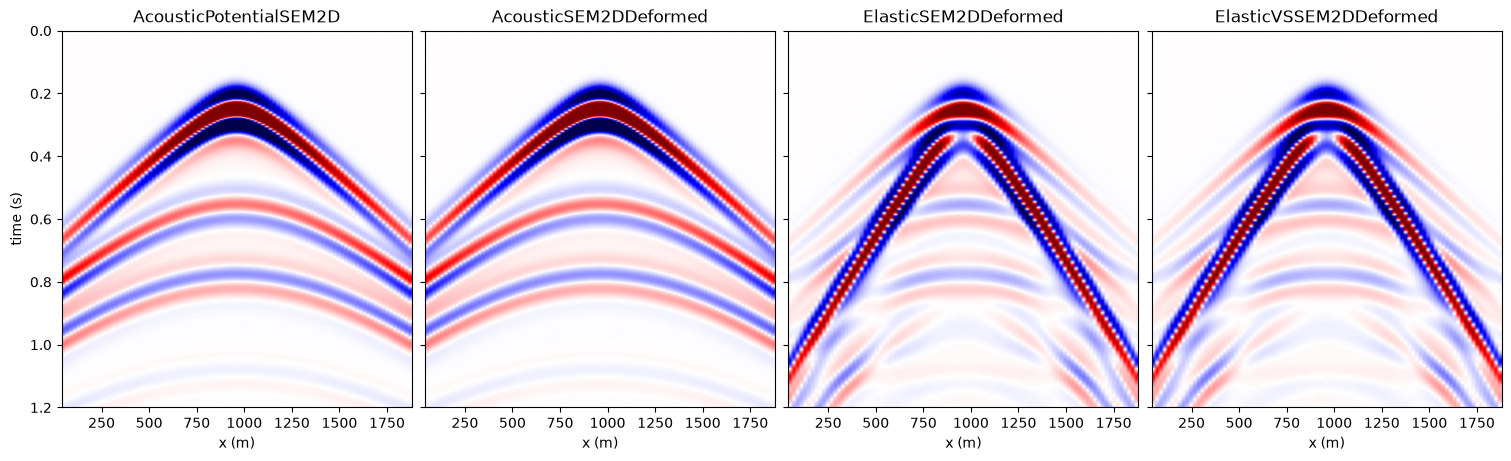

In [6]:
def show(ax, g, title):
    v = np.percentile(np.abs(g), 98)
    ax.imshow(g, cmap='seismic', vmin=-v, vmax=v, aspect='auto',
              extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
    ax.set_title(title); ax.set_xlabel('x (m)')

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), sharey=True, constrained_layout=True)
for ax, (name, g) in zip(axes, records.items()):
    show(ax, g, name)
axes[0].set_ylabel('time (s)')
plt.show()

The two acoustic records show the direct wave, the reflection from the layer
boundary at 480 m and the free-surface ghosts and multiples. The two elastic
ones add converted and shear waves and the Rayleigh wave along the surface.
Within each pair the formulation differs but the physics is the same, so the
traces agree in shape. Their amplitude scales are not the same (each equation
has its own source normalization), so compare them normalized:

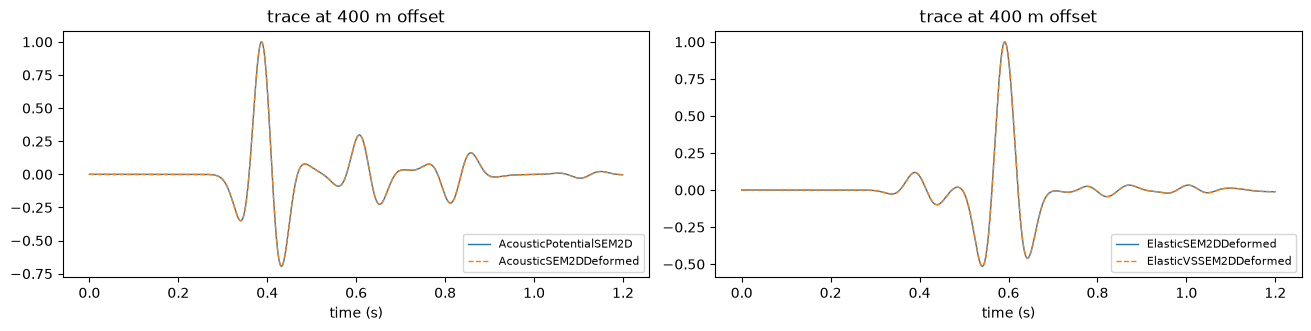

AcousticPotentialSEM2D vs AcousticSEM2DDeformed: relative difference of the normalized gathers 6.3e-06
ElasticSEM2DDeformed vs ElasticVSSEM2DDeformed: relative difference of the normalized gathers 2.1e-02


In [7]:
k = np.argmin(np.abs(rx - (src[0, 0] + 40)))          # 400 m offset
t = np.arange(nt) * dt
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), constrained_layout=True)
for ax, pair in zip(axes, [('AcousticPotentialSEM2D', 'AcousticSEM2DDeformed'),
                           ('ElasticSEM2DDeformed', 'ElasticVSSEM2DDeformed')]):
    for name, ls in zip(pair, ['-', '--']):
        tr = records[name][:, k]
        ax.plot(t, tr / np.abs(tr).max(), ls, lw=1, label=name)
    ax.set_xlabel('time (s)'); ax.legend(loc='lower right', fontsize=8)
    ax.set_title(f'trace at {(rx[k] - src[0, 0]) * dh:.0f} m offset')
plt.show()
for a, b in [('AcousticPotentialSEM2D', 'AcousticSEM2DDeformed'),
             ('ElasticSEM2DDeformed', 'ElasticVSSEM2DDeformed')]:
    ga, gb = records[a], records[b]
    ga, gb = ga / np.abs(ga).max(), gb / np.abs(gb).max()
    print(f'{a} vs {b}: relative difference of the normalized gathers '
          f'{np.linalg.norm(ga - gb) / np.linalg.norm(ga):.1e}')

The acoustic pair agrees to single-precision round-off, since the same wavelet
is the pressure source of both; the elastic pair, a displacement and a
velocity–stress discretization, to 2%. Only the scale of the acoustic pair
differs: the potential form's pressure
carries the bulk modulus `kappa = rho vp^2` at the source (SPECFEM's
normalization, with `rho` the `density=` of `PropSEM`), the pressure form's does
not. The ratio of the two records is that number:

In [8]:
peak = {name: np.abs(records[name]).max()
        for name in ('AcousticPotentialSEM2D', 'AcousticSEM2DDeformed')}
kappa = 1000.0 * float(vp[src[0, 1], src[0, 0]]) ** 2      # density 1000 (the default) x vp^2
print(f"peak |p|: potential form {peak['AcousticPotentialSEM2D']:.4g}, "
      f"pressure form {peak['AcousticSEM2DDeformed']:.4g}")
print(f"ratio {peak['AcousticPotentialSEM2D'] / peak['AcousticSEM2DDeformed']:.4g}, "
      f"kappa at the source {kappa:.4g}")

peak |p|: potential form 87.69, pressure form 2.706e-08
ratio 3.24e+09, kappa at the source 3.24e+09


So dividing the potential form's record by `kappa` at the source gives the
pressure form's, and an FD acoustic run's. In an inversion the scale does not
matter once the wavelet is scaled to the data (as in
[SEM gradients](../54_sem_gradients_and_memory/)). `receiver_type=['chi']` still
records the potential itself, the wavelet's double time integral: a slow tail
that is a poor record to fit, so it is not the default.

## 4. SH waves

`ElasticSHSEM2DDeformed` solves for the out-of-plane displacement `u_y` of a
medium that does not change along y (SPECFEM2D's `P_SV = .false.`). In 2-D this
motion does not couple to the in-plane P–SV motion of the other elastic
equations. It takes `[vs, rho]`, its source is a force along y, it records
`u_y` or its velocity `vy`, and its free surface is traction-free. On the same
model, next to the vertical force of `ElasticSEM2DDeformed` from section 3:

models: ['vs', 'rho']   source: ['u_y']   impl: eager


sweep: torch.compile is compiling the ElasticSHSEM2DDeformed step for a 97x193 grid


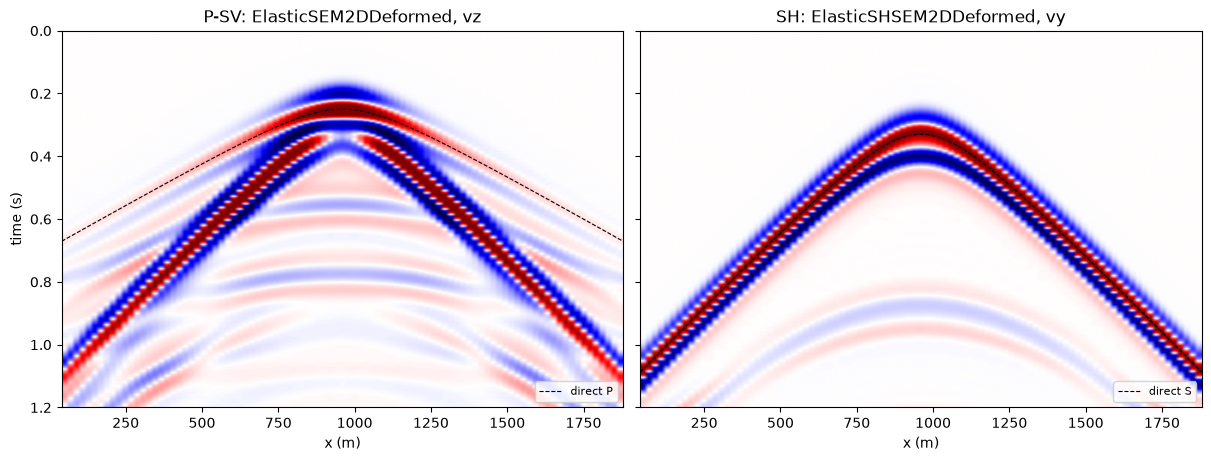

In [9]:
sh = PropSEM(ElasticSHSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order, abcn=40,
             free_surface=True, f_dominant=f0, receiver_type=['vy'], device=device)
print('models:', sh.model_names, '  source:', sh.source_type, '  impl:', sh.impl)
with torch.no_grad():
    vy = sh(wavelet, src, rec, models=[vs, rho])[0, :, :, 0].cpu().numpy()

offset = (rx - src[0, 0]) * dh
depth = (src[0, 1] - rec[0, 0, 1]) * dh                 # 180 m from the source up to the receivers
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)
for ax, g, title, v, wave in [
        (axes[0], records['ElasticSEM2DDeformed'], 'P-SV: ElasticSEM2DDeformed, vz', 1800.0, 'direct P'),
        (axes[1], vy, 'SH: ElasticSHSEM2DDeformed, vy', 1000.0, 'direct S')]:
    show(ax, g, title)
    ax.plot(rx * dh, np.hypot(offset, depth) / v + 1.2 / f0, 'k--', lw=0.8, label=wave)
    ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('time (s)')
plt.show()

The SH record holds S waves only: the direct S wave (dashed, 1000 m/s from the
source 180 m below the receivers) and, from about 0.9 s at zero offset, the
reflection from the layer boundary at 480 m. The P wave and the Rayleigh wave are
in-plane motion and do not appear. The class runs on eager, flat or under a
topography, and takes `interfaces=` ([SEM mesh and time step](../50_sem_mesh_and_time_step/)).

## Summary

- Pick the equation by physics (acoustic, elastic, SH, anisotropic, attenuating,
  fluid–solid, poroelastic) and by backend: the `impl='c'` ones are the fast
  choice for many shots and inversion; the rest run eager.
- `solver.model_names` is the `models=` list, in order; models are grid tensors
  of `shape`.
- On the acoustic forms the wavelet is the pressure source and `p` the record;
  the potential form's `p` is `kappa` times the pressure form's.
- Changing the equation is a change of the class (and of `models=`); the call
  and the record layout `(nshots, nt, nrec, ncomp)` stay the same.

Next: [SEM sources and receivers · positions, types and shots](../52_sem_sources_and_receivers/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="51_sem_equations_and_models.ipynb" download><code>51_sem_equations_and_models.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/51_sem_equations_and_models.ipynb">view on GitHub</a></p>